In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
n_comps, n_DHSs = decomp_Mixture.shape

In [3]:
#results from fill in 0.01%
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_2_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_new_decomp_Mixture_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
new_decomp_Mixture_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [33]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy()
del dhs

#results from fill in 0.01%
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_3_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_3_cycles=pickle.load(pickle_in)

(733, 3591898)


In [4]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


**Top 10% DHSs for each Mixture**

In [5]:
#quantitatively comparing mixture embeddings
cycle_0_mixture_top_10_percent = decomp_Mixture[:, top_10_percent_DHSs_inds]
cycle_1_mixture_top_10_percent = new_decomp_Mixture_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]
cycle_2_mixture_top_10_percent = new_decomp_Mixture_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds]
cycle_3_mixture_top_10_percent = new_decomp_Mixture_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds]

**Top comp of top 10% mixtures**

In [6]:
cycle_1_mixture_top_10_percent_sum = np.sum(cycle_1_mixture_top_10_percent, axis=0)
cycle_2_mixture_top_10_percent_sum = np.sum(cycle_2_mixture_top_10_percent, axis=0)
cycle_3_mixture_top_10_percent_sum = np.sum(cycle_3_mixture_top_10_percent, axis=0)

cycle_1_mixture_top_10_percent_not_all_0_inds = np.where(cycle_1_mixture_top_10_percent_sum!=0)[0]
cycle_2_mixture_top_10_percent_not_all_0_inds = np.where(cycle_2_mixture_top_10_percent_sum!=0)[0]
cycle_3_mixture_top_10_percent_not_all_0_inds = np.where(cycle_3_mixture_top_10_percent_sum!=0)[0]

In [7]:
#not filtered top comps
cycle_0_mixture_top_10_percent_top_comp = np.argmax(cycle_0_mixture_top_10_percent, axis=0)
cycle_1_mixture_top_10_percent_top_comp = np.argmax(cycle_1_mixture_top_10_percent, axis=0)
cycle_2_mixture_top_10_percent_top_comp = np.argmax(cycle_2_mixture_top_10_percent, axis=0)
cycle_3_mixture_top_10_percent_top_comp = np.argmax(cycle_3_mixture_top_10_percent, axis=0)

**Heatmaps (of just DHSs that change component)**

In [8]:
cycle_1_cycle_0_top_10_percent_top_comp_array = np.zeros((16,16), dtype=int)
for comp1, comp0 in zip(cycle_1_mixture_top_10_percent_top_comp[cycle_1_mixture_top_10_percent_not_all_0_inds],
               cycle_0_mixture_top_10_percent_top_comp[cycle_1_mixture_top_10_percent_not_all_0_inds]):
    if comp1!=comp0:
        cycle_1_cycle_0_top_10_percent_top_comp_array[comp1, comp0]+=1
        
cycle_2_cycle_1_top_10_percent_top_comp_array = np.zeros((16,16), dtype=int)
for comp2, comp1 in zip(cycle_2_mixture_top_10_percent_top_comp[cycle_2_mixture_top_10_percent_not_all_0_inds],
               cycle_1_mixture_top_10_percent_top_comp[cycle_2_mixture_top_10_percent_not_all_0_inds]):
    if comp2!=comp1:
        cycle_2_cycle_1_top_10_percent_top_comp_array[comp2, comp1]+=1
        
cycle_3_cycle_2_top_10_percent_top_comp_array = np.zeros((16,16), dtype=int)
for comp3, comp2 in zip(cycle_3_mixture_top_10_percent_top_comp[cycle_3_mixture_top_10_percent_not_all_0_inds],
               cycle_2_mixture_top_10_percent_top_comp[cycle_3_mixture_top_10_percent_not_all_0_inds]):
    if comp3!=comp2:
        cycle_3_cycle_2_top_10_percent_top_comp_array[comp3, comp2]+=1

In [9]:
# cycle_3_cycle_2_top_10_percent_top_comp_array = np.zeros((16,16), dtype=int)
# cycle_3_cycle_2_top_10_percent_top_comp_array[3, 0]=1

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Cycle 0 and Cycle 1 NMF Mixtures\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs')

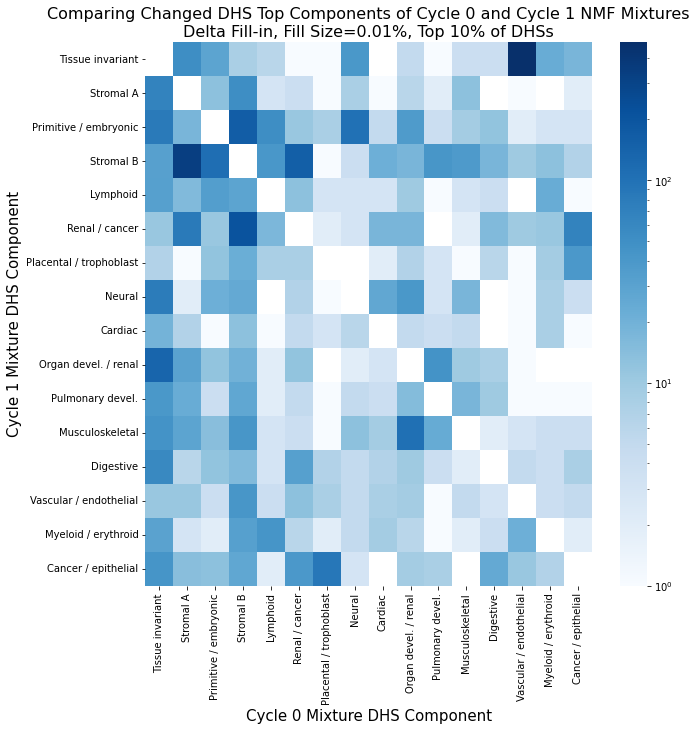

In [10]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(cycle_1_cycle_0_top_10_percent_top_comp_array, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('Cycle 1 Mixture DHS Component', fontsize=15)
ax.set_xlabel('Cycle 0 Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Cycle 0 and Cycle 1 NMF Mixtures\nDelta Fill-in, Fill Size=0.01%, Top 10% of DHSs', fontsize=16)

**Measuring DHS mixture purity**

In [11]:
#different options for purity:
#1 top value / average
#2 top value / 2nd largest value
#3 top value / sum

In [12]:
#filtering out all 0 DHSs from mixtures
# cycle_1_mixture_top_10_percent_top_comp_filtered = cycle_1_mixture_top_10_percent_top_comp[cycle_1_mixture_top_10_percent_not_all_0_inds]
# cycle_2_mixture_top_10_percent_top_comp_filtered = cycle_2_mixture_top_10_percent_top_comp[cycle_2_mixture_top_10_percent_not_all_0_inds]
# cycle_3_mixture_top_10_percent_top_comp_filtered = cycle_3_mixture_top_10_percent_top_comp[cycle_3_mixture_top_10_percent_not_all_0_inds]

cycle_1_mixture_top_10_percent_filtered = cycle_1_mixture_top_10_percent[:, cycle_1_mixture_top_10_percent_not_all_0_inds]
cycle_2_mixture_top_10_percent_filtered = cycle_2_mixture_top_10_percent[:, cycle_2_mixture_top_10_percent_not_all_0_inds]
cycle_3_mixture_top_10_percent_filtered = cycle_3_mixture_top_10_percent[:, cycle_3_mixture_top_10_percent_not_all_0_inds]

In [13]:
#finding value of top comp
cycle_0_mixture_top_10_percent_top_comp_value = np.max(cycle_0_mixture_top_10_percent, axis=0)
cycle_1_mixture_top_10_percent_filtered_top_comp_value = np.max(cycle_1_mixture_top_10_percent_filtered, axis=0)
cycle_2_mixture_top_10_percent_filtered_top_comp_value = np.max(cycle_2_mixture_top_10_percent_filtered, axis=0)
cycle_3_mixture_top_10_percent_filtered_top_comp_value = np.max(cycle_3_mixture_top_10_percent_filtered, axis=0)

In [14]:
#finding average of all comps
cycle_1_mixture_top_10_percent_filtered_mean = np.mean(cycle_1_mixture_top_10_percent_filtered, axis=0)
cycle_2_mixture_top_10_percent_filtered_mean = np.mean(cycle_2_mixture_top_10_percent_filtered, axis=0)
cycle_3_mixture_top_10_percent_filtered_mean = np.mean(cycle_3_mixture_top_10_percent_filtered, axis=0)

In [15]:
#finiding sum of all comps
cycle_0_mixture_top_10_percent_sum = np.sum(cycle_0_mixture_top_10_percent, axis=0)
cycle_1_mixture_top_10_percent_filtered_sum = np.sum(cycle_1_mixture_top_10_percent_filtered, axis=0)
cycle_2_mixture_top_10_percent_filtered_sum = np.sum(cycle_2_mixture_top_10_percent_filtered, axis=0)
cycle_3_mixture_top_10_percent_filtered_sum = np.sum(cycle_3_mixture_top_10_percent_filtered, axis=0)

In [16]:
#finding second largest value
cycle_0_mixture_top_10_percent_second_top_comp_value = []
for dhs in range(len(cycle_0_mixture_top_10_percent[0,:])):
    second_largest_ind = np.argsort(cycle_0_mixture_top_10_percent[:, dhs])[-2]
    cycle_0_mixture_top_10_percent_second_top_comp_value.append(cycle_0_mixture_top_10_percent[second_largest_ind, dhs])
cycle_0_mixture_top_10_percent_second_top_comp_value = np.array(cycle_0_mixture_top_10_percent_second_top_comp_value)

cycle_1_mixture_top_10_percent_filtered_second_top_comp_value = []
for dhs in range(len(cycle_1_mixture_top_10_percent_filtered[0,:])):
    second_largest_ind = np.argsort(cycle_1_mixture_top_10_percent_filtered[:, dhs])[-2]
    cycle_1_mixture_top_10_percent_filtered_second_top_comp_value.append(cycle_1_mixture_top_10_percent_filtered[second_largest_ind, dhs])
cycle_1_mixture_top_10_percent_filtered_second_top_comp_value = np.array(cycle_1_mixture_top_10_percent_filtered_second_top_comp_value)

cycle_2_mixture_top_10_percent_filtered_second_top_comp_value = []
for dhs in range(len(cycle_2_mixture_top_10_percent_filtered[0,:])):
    second_largest_ind = np.argsort(cycle_2_mixture_top_10_percent_filtered[:, dhs])[-2]
    cycle_2_mixture_top_10_percent_filtered_second_top_comp_value.append(cycle_2_mixture_top_10_percent_filtered[second_largest_ind, dhs])
cycle_2_mixture_top_10_percent_filtered_second_top_comp_value = np.array(cycle_2_mixture_top_10_percent_filtered_second_top_comp_value)

cycle_3_mixture_top_10_percent_filtered_second_top_comp_value = []
for dhs in range(len(cycle_3_mixture_top_10_percent_filtered[0,:])):
    second_largest_ind = np.argsort(cycle_3_mixture_top_10_percent_filtered[:, dhs])[-2]
    cycle_3_mixture_top_10_percent_filtered_second_top_comp_value.append(cycle_3_mixture_top_10_percent_filtered[second_largest_ind, dhs])
cycle_3_mixture_top_10_percent_filtered_second_top_comp_value = np.array(cycle_3_mixture_top_10_percent_filtered_second_top_comp_value)

In [21]:
cycle_0_purity_by_sum = cycle_0_mixture_top_10_percent_top_comp_value / cycle_0_mixture_top_10_percent_sum
cycle_1_purity_by_sum = cycle_1_mixture_top_10_percent_filtered_top_comp_value / cycle_1_mixture_top_10_percent_filtered_sum
cycle_2_purity_by_sum = cycle_2_mixture_top_10_percent_filtered_top_comp_value / cycle_2_mixture_top_10_percent_filtered_sum
cycle_3_purity_by_sum = cycle_3_mixture_top_10_percent_filtered_top_comp_value / cycle_3_mixture_top_10_percent_filtered_sum

(0.0, 1.0)

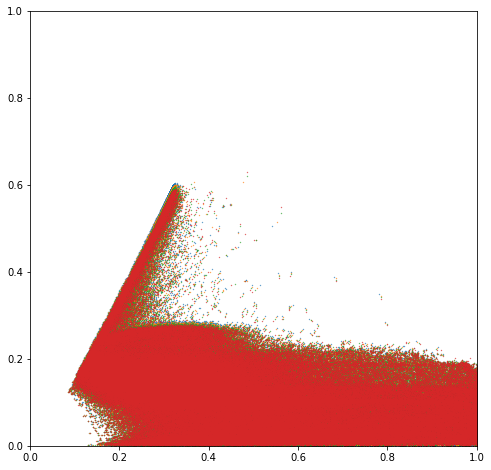

In [48]:
#maybe purity vs number of samples
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.scatter(cycle_0_purity_by_sum, cycle_0_mixture_top_10_percent_top_comp_value, s=0.1)
plt.scatter(cycle_1_purity_by_sum, cycle_1_mixture_top_10_percent_filtered_top_comp_value, s=0.1)
plt.scatter(cycle_2_purity_by_sum, cycle_2_mixture_top_10_percent_filtered_top_comp_value, s=0.1)
plt.scatter(cycle_3_purity_by_sum, cycle_3_mixture_top_10_percent_filtered_top_comp_value, s=0.1)
plt.xlim([0, 1])
plt.ylim([0, 1])

# plt.ylabel('0.01% Delta Value')
# plt.xlabel('1 at a Time, Total NMF Delta Value')
# plt.title('Comparing Delta Values Between 0.01% and 1 at a Time Methods')

**Number of samples vs NMF Mixture Loadings**

In [32]:
cycle_1_mixture_top_10_percent_filtered = cycle_1_mixture_top_10_percent[:, cycle_1_mixture_top_10_percent_not_all_0_inds]
cycle_2_mixture_top_10_percent_filtered = cycle_2_mixture_top_10_percent[:, cycle_2_mixture_top_10_percent_not_all_0_inds]
cycle_3_mixture_top_10_percent_filtered = cycle_3_mixture_top_10_percent[:, cycle_3_mixture_top_10_percent_not_all_0_inds]

#finiding sum of all comps
cycle_0_mixture_top_10_percent_sum = np.sum(cycle_0_mixture_top_10_percent, axis=0)
cycle_1_mixture_top_10_percent_filtered_sum = np.sum(cycle_1_mixture_top_10_percent_filtered, axis=0)
cycle_2_mixture_top_10_percent_filtered_sum = np.sum(cycle_2_mixture_top_10_percent_filtered, axis=0)
cycle_3_mixture_top_10_percent_filtered_sum = np.sum(cycle_3_mixture_top_10_percent_filtered, axis=0)

In [37]:
#top 10% of dhss
dhs_array_top_10_percent = dhs_array[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered = updated_dhs_array_all_delta_0001_1_cycle[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_2_cycles[:, top_10_percent_DHSs_inds]
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_3_cycles[:, top_10_percent_DHSs_inds]
#filtering these DHS arrays such that we are only looking at DHSs with biosample representation
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered = updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered[:, cycle_1_mixture_top_10_percent_not_all_0_inds]
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered[:, cycle_2_mixture_top_10_percent_not_all_0_inds]
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered = updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered[:, cycle_3_mixture_top_10_percent_not_all_0_inds]

In [40]:
dhs_array_top_10_percent_numsamples = np.sum(dhs_array_top_10_percent, axis=0)
updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered, axis=0)
updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered, axis=0)
updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered_numsamples = np.sum(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered, axis=0)

Text(0.5, 1.0, 'Comparing Number of Samples to Sum of NMF Mixture Loading\nDelta Fill-in, Fill Size=0.01%')

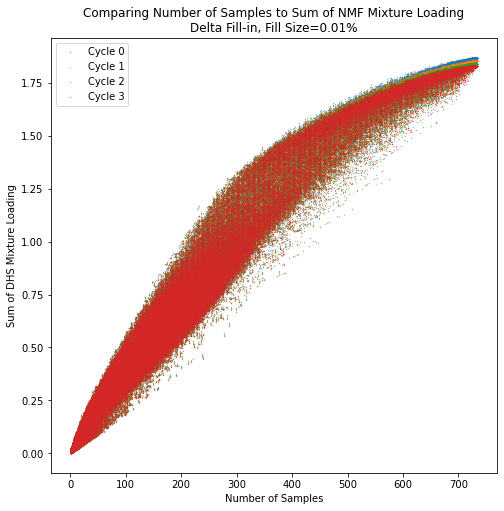

In [61]:
fig = plt.figure(figsize=(8,8))
fig.patch.set_facecolor('white')

plt.scatter(dhs_array_top_10_percent_numsamples, cycle_0_mixture_top_10_percent_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_1_cycle_top_10_percent_filtered_numsamples, cycle_1_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_2_cycles_top_10_percent_filtered_numsamples, cycle_2_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)
plt.scatter(updated_dhs_array_all_delta_0001_3_cycles_top_10_percent_filtered_numsamples, cycle_3_mixture_top_10_percent_filtered_sum, s=0.1, alpha=0.8)


plt.legend(['Cycle 0', 'Cycle 1', 'Cycle 2', 'Cycle 3'])
plt.xlabel('Number of Samples')
plt.ylabel('Sum of DHS Mixture Loading')
plt.title('Comparing Number of Samples to Sum of NMF Mixture Loading\nDelta Fill-in, Fill Size=0.01%')